# Hoppers Lab: learning to play by imitating experts

In the tournament your agent played well because **you** wrote its heuristic.
Here the agent learns to play from **examples**: about 40,000 moves played by
the six agents of the tournament. This is **imitation learning**
(*behavioral cloning*), the standard first step for learning a game with
machine learning; AlphaGo started the same way.

The model learns to answer one question:

> **Given this board and this move, would an expert play it?**

To play, the agent asks it for every valid move and plays the best-scored one.
At the end, the notebook saves your trained model (`my_model.keras` or
`my_model.joblib`) and writes **`my_ml_agent.py`**, an agent that loads it and
plays in the tournament.

| part | what | you do |
|---|---|---|
| 0 | setup (Colab: upload 2 files) | run |
| 1 | the data | run |
| 2 | how the agent decides; why it never plays an illegal move | run |
| 3 | two ways to turn (board, move) into numbers: **(a)** the board, **(b)** 10 features | run |
| 4 | the training table | run |
| 5 | **logistic regression** | **Exercise 1** |
| 6 | **neural network** | **Exercises 2-3** |
| 7 | the agent, and which model plays best | **Exercise 4** |
| 8 | save the model and write `my_ml_agent.py` for the tournament | run |

Videos with the same idea in other games:

[What is Behavioral Cloning?](https://www.youtube.com/watch?v=yAnzAehMwF4) ·
[A chess engine with TensorFlow](https://www.youtube.com/watch?v=v3jMr0Ppd9Y)

## Part 0. Setup

You need **two files** next to this notebook:

- `hoppers_moves.npz`: the expert moves (the data);
- `hopperstournament.py`: the rules of the game, the same file as in the tournament.

**In Google Colab**, run the next cell and choose both files when it asks.
**On your computer**, put them in the same folder as the notebook; the cell then does nothing.

In [24]:
import os, sys
if "google.colab" in sys.modules and not (os.path.exists("hoppers_moves.npz") and os.path.exists("hopperstournament.py")):
    from google.colab import files
    print("Choose hoppers_moves.npz and hopperstournament.py")
    for name, content in files.upload().items():
        for wanted in ("hoppers_moves.npz", "hopperstournament.py"):
            if name.startswith(wanted.split(".")[0]):          # Colab may rename it "hoppers_moves (1).npz"
                open(wanted, "wb").write(content)
print("files ready:", os.path.exists("hoppers_moves.npz") and os.path.exists("hopperstournament.py"))

files ready: True


In [25]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # hide TensorFlow's info messages
import random, time
import numpy as np
import matplotlib.pyplot as plt
import hopperstournament as H
np.random.seed(0)

## Part 1. The data

How it was made:

1. **6  agents** of the class tournament (minimax agents, each with
   its own heuristic; names anonymized as Agente A to F) played **437 games**
   against each other, about 1 second per move.
2. Each game began with **0 to 8 random moves**, so two deterministic agents would
   not play the same game over and over. Then the agents played alone until
   someone filled the opponent's camp.
3. Before every move the board was recorded, together with the piece that moved:
   from where (**origin**) and to where (**destination**).
4. The random opening moves were removed (no expert chose them). The moves of
   **both** players are kept: all six are experts.

The result is `hoppers_moves.npz`, **one row per expert move**:

| field | shape | meaning |
|---|---|---|
| `board` | (N, 10, 10) | the board **before** the move: 0 empty, 1 = P1, 2 = P2 |
| `to_move` | (N,) | who moved: 1 or 2 |
| `origin` | (N, 2) | (row, col) the piece left |
| `dest` | (N, 2) | (row, col) the piece reached |
| `game_id` | (N,) | which game |
| `ply` | (N,) | move number inside the game |

P1 starts top-left and runs to the corner (9, 9); P2 starts bottom-right and runs to (0, 0).

In [26]:
data = np.load("hoppers_moves.npz")
for k in data.files:
    print(f"{k:8s} {str(data[k].dtype):6s} {data[k].shape}")
print("games:", len(np.unique(data["game_id"])), "| expert moves:", len(data["board"]))

board    uint8  (40063, 10, 10)
to_move  uint8  (40063,)
origin   int8   (40063, 2)
dest     int8   (40063, 2)
game_id  int16  (40063,)
ply      int16  (40063,)
games: 437 | expert moves: 40063


One expert move: `*` is where the piece was, `@` where it went.

In [27]:
def show(board, origin=None, dest=None):
    print("    " + " ".join(str(c) for c in range(10)))
    for r in range(10):
        row = []
        for c in range(10):
            ch = ".12"[board[r][c]]
            if (r, c) == origin: ch = "*"
            if (r, c) == dest: ch = "@"
            row.append(ch)
        print(f" {r}  " + " ".join(row))

i = 2000
print("player to move:", data["to_move"][i], "| game", data["game_id"][i], "move", data["ply"][i])
show(data["board"][i], tuple(data["origin"][i]), tuple(data["dest"][i]))

player to move: 2 | game 19 move 5
    0 1 2 3 4 5 6 7 8 9
 0  1 1 1 1 1 . . . . .
 1  . . 1 1 . . . . . .
 2  1 . 1 . . . . . . .
 3  1 1 . . . @ . . . .
 4  . . 1 . . . 2 . . .
 5  . . 1 . . . 2 . . 2
 6  . . . 1 . . . 2 2 .
 7  . . . 1 . . . 2 . *
 8  . . . . . 2 2 . . 2
 9  . . . . . 2 2 2 2 2


**Train and validation by game.** We keep 20% of the **games** apart to check
the models on games they never saw. Whole games, not single moves: two moves of
the same game have almost the same board, so mixing them would make the check
look better than it is.

In [28]:
def to_state(board, to_move):
    return H.State(tuple(tuple(int(v) for v in row) for row in board), int(to_move))

def load_samples(data):
    # each expert move as (state, valid moves, index of the expert's move, game)
    out = []
    for b, m, o, d, g in zip(data["board"], data["to_move"], data["origin"], data["dest"], data["game_id"]):
        state = to_state(b, m)
        moves = H.actions(state)
        idx = next(k for k, a in enumerate(moves) if a.origin == tuple(o) and a.destination == tuple(d))
        out.append((state, moves, idx, int(g)))
    return out

t = time.time()
samples = load_samples(data)
games = np.unique(data["game_id"])
np.random.default_rng(0).shuffle(games)
val_games = set(games[: len(games) // 5].tolist())
train = [(s, m, i) for s, m, i, g in samples if g not in val_games]
val = [(s, m, i) for s, m, i, g in samples if g in val_games]
print(f"train: {len(train)} moves   validation: {len(val)} moves from {len(val_games)} games   ({time.time() - t:.0f}s)")

train: 32399 moves   validation: 7664 moves from 87 games   (20s)


## Part 2. How the agent decides, and how it knows what is valid

The model **does not know the rules** and **never invents a move**. The rules
(`hopperstournament.py`) list the valid moves; the model only scores them:

```
          the rules                    the model                       the agent
  state ─────────────► valid moves ──────────────► one score per move ──────────► the move with
        H.actions(state)  (60-100)    "would an expert              the highest score
                                       play this one?"
```

Because the agent only chooses **from that list**, it can never play an illegal
move (AlphaZero calls this *masking*). One extra
rule: if a valid move **wins right now**, play it.

In [29]:
state, moves, idx = val[0]
print(f"{len(moves)} valid moves in this position, for example:")
for a in moves[:5]:
    print("   ", a, " (hop)" if a.is_hop() else " (step)")
print("the expert played:", moves[idx])

99 valid moves in this position, for example:
    (0,0) -> (1,1)  (step)
    (0,0) -> (0,2)  (hop)
    (0,0) -> (0,2) -> (2,4)  (hop)
    (0,1) -> (0,2)  (step)
    (0,1) -> (1,1)  (step)
the expert played: (1,0) -> (3,0) -> (1,2) -> (1,4)


## Part 3. Turning (board, move) into numbers

A model only reads numbers, so every (board, move) becomes **one row of numbers**.

**(a) the board: 400 numbers.** Four 10x10 pictures of 0s and 1s, one after the other:

| numbers | picture | a 1 means |
|---|---|---|
| 0-99 | my pieces | one of my pieces is on that square |
| 100-199 | their pieces | an opponent's piece is on that square |
| 200-299 | origin | the move starts here (exactly one 1) |
| 300-399 | destination | the move ends here (exactly one 1) |

Square (row, col) is number `10*row + col` inside each picture.

**(b) 10 features**: things a person thinks matter (how much it advances, if it
hops, if it enters the target camp, ...).

**Always from the point of view of the player to move.** When player 2 moves,
the board is rotated 180 degrees: (r, c) becomes (9 - r, 9 - c). Then both
players run to (9, 9) and one model plays both colors.

The next cell **writes this code to a file**, `hoppers_inputs.py`, and loads it.
It is the code your tournament agent will carry with it (Part 8), so the agent
turns boards into numbers exactly as in training.

In [30]:
%%writefile hoppers_inputs.py
import numpy as np
from hopperstournament import P1, P2, actions, in_camp, opponent, pieces_of, result, winner

GOAL = {P1: (9, 9), P2: (0, 0)}


def canon(player, r, c):
    """Square (r, c) as `player` sees it: player 2 sees the board rotated."""
    return (9 - r, 9 - c) if player == P2 else (r, c)


def encode_board(state, moves):
    """(a) 400 numbers per move: my pieces, their pieces, origin, destination."""
    me = state.to_move
    board = np.array(state.board, dtype=np.int8)
    if me == P2:
        board = board[::-1, ::-1]
    X = np.zeros((len(moves), 400), dtype=np.float32)
    X[:, :100] = (board == me).ravel()
    X[:, 100:200] = (board == opponent(me)).ravel()
    for i, a in enumerate(moves):
        r0, c0 = canon(me, *a.origin)
        r1, c1 = canon(me, *a.destination)
        X[i, 200 + 10 * r0 + c0] = 1.0
        X[i, 300 + 10 * r1 + c1] = 1.0
    return X


def cheb(a, b):
    """Single steps between two squares (pieces also move diagonally)."""
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))


def _targets(p):
    sr, sc = GOAL[opponent(p)]
    sign = 1 if p == P1 else -1
    cells = [(r, c) for r in range(10) for c in range(10) if in_camp(opponent(p), r, c)]
    cells.sort(key=lambda x: (-cheb(x, (sr, sc)), sign * (x[0] - x[1])))
    return cells


_TARGETS = {P1: _targets(P1), P2: _targets(P2)}


def travel(state, p):
    """Steps player p still needs to fill the target camp (the course heuristic)."""
    gr, gc = GOAL[p]
    sign = 1 if p == P1 else -1
    remaining = sorted(pieces_of(state, p), key=lambda x: (cheb(x, (gr, gc)), sign * (x[0] - x[1])))
    total = 0
    for t in _TARGETS[p]:
        if not remaining:
            break
        best_i, best_d = 0, None
        for i, cell in enumerate(remaining):
            d = cheb(cell, t)
            if best_d is None or d < best_d:
                best_i, best_d = i, d
            if d == 0:
                break
        total += best_d
        remaining.pop(best_i)
    return total


FEATURES = [
    "gain",             # steps this move saves in my remaining travel (the course heuristic)
    "advance",          # how much closer to the goal corner the piece gets
    "is_hop",           # 1 if it jumps, 0 if it steps
    "hops",             # number of jumps in the chain (0 for a step)
    "leaves_home",      # 1 if the piece leaves my starting camp
    "enters_target",    # 1 if the piece enters the camp I must fill
    "moves_in_target",  # 1 if the piece was already in the target camp
    "behind",           # how far ahead this piece is of my LAST piece (0 = it is my last piece)
    "dest_goal_dist",   # steps from the destination to the goal corner
    "dest_off_diag",    # distance of the destination from the main diagonal (0 = on it)
]


def encode_features(state, moves):
    """(b) 10 numbers per move, in the order of FEATURES.

    Everything is seen from the player to move ("me"), with the board rotated for
    player 2, so my goal corner is always (9, 9) and my home corner (0, 0).
    A handy number: r + c, the "diagonal" of a square. It is 0 at my home corner
    and 18 at my goal corner, so a bigger r + c means further forward.
      - my home camp (where I start)       = the 15 squares with r + c <= 4
      - the target camp (where I must go)  = the 15 squares with r + c >= 14
    """
    me = state.to_move

    # Computed once per position (they do not depend on the move):
    base = travel(state, me)               # steps I still need to fill the target camp, before moving
    last = min(sum(canon(me, r, c))        # diagonal of my most-behind piece
               for r, c in pieces_of(state, me))

    X = np.zeros((len(moves), len(FEATURES)), dtype=np.float32)   # one row per move
    for i, a in enumerate(moves):
        r0, c0 = canon(me, *a.origin)          # where the piece starts (my point of view)
        r1, c1 = canon(me, *a.destination)     # where the piece ends
        d0, d1 = r0 + c0, r1 + c1              # diagonal before and after the move
        hop = a.is_hop()

        gain = base - travel(result(state, a), me)   # steps the move saves me (the course heuristic);
                                                     # it can be negative if the move goes backwards
        advance = d1 - d0                            # how many diagonals the piece moves forward
        is_hop = float(hop)                          # 1 = jump, 0 = single step
        hops = len(a.path) - 1 if hop else 0         # jumps in the chain (path = origin + each landing square)
        leaves_home = float(d0 <= 4 < d1)            # 1 if the piece starts in my home camp and leaves it
        enters_target = float(d0 < 14 <= d1)         # 1 if the piece was outside the target camp and gets in
        moves_in_target = float(d0 >= 14)            # 1 if the piece was already in the target camp
        behind = d0 - last                           # how far ahead this piece is of my last piece
                                                     # (0 = it IS my last piece, the one that may get stuck)
        dest_goal_dist = max(9 - r1, 9 - c1)         # single steps from the destination to the goal corner
        dest_off_diag = abs(r1 - c1)                 # distance from the destination to the main diagonal
                                                     # (0 = on the diagonal, the shortest road to the goal)

        X[i] = (gain, advance, is_hop, hops, leaves_home,
                enters_target, moves_in_target, behind, dest_goal_dist, dest_off_diag)
    return X


ENCODERS = {"a": encode_board, "b": encode_features}

Overwriting hoppers_inputs.py


In [31]:
import importlib, hoppers_inputs
importlib.reload(hoppers_inputs)
from hoppers_inputs import encode_board, encode_features, FEATURES, ENCODERS

xa = encode_board(state, [moves[idx]])[0]
xb = encode_features(state, [moves[idx]])[0]
print("the expert's move from Part 2, both ways\n")
print("(a)", xa.shape, "->", int(xa.sum()), "ones")
pics = xa.reshape(4, 10, 10)
print("   ".join(f"{t:^19s}" for t in ["mine", "theirs", "origin", "destination"]))
for r in range(10):
    print("   ".join(" ".join("#" if pics[p, r, c] else "." for c in range(10)) for p in range(4)))
print("\n(b)", xb.shape)
for n, v in zip(FEATURES, xb):
    print(f"   {n:16s} {v:5.1f}")

the expert's move from Part 2, both ways

(a) (400,) -> 32 ones
       mine                 theirs                origin              destination    
# # . . # . . . . .   . . . . . . . . . .   . . . . . . . . . .   . . . . . . . . . .
# . . # . . . . . .   . . . . . . . . . .   # . . . . . . . . .   . . . . # . . . . .
# # # # . . . . . .   . . . . . . . . . .   . . . . . . . . . .   . . . . . . . . . .
. # . . # . . . . .   . . . . . . . . . .   . . . . . . . . . .   . . . . . . . . . .
# # . . # . . . . .   . . . . . # . . # .   . . . . . . . . . .   . . . . . . . . . .
. . . . . # . . . .   . . . . . . . # . .   . . . . . . . . . .   . . . . . . . . . .
. . . . . . . . . .   . . . . . . # . # #   . . . . . . . . . .   . . . . . . . . . .
. . . . . . . . . .   . . . . . . . # # .   . . . . . . . . . .   . . . . . . . . . .
. . . . . . . . . .   . . . . . . # # . .   . . . . . . . . . .   . . . . . . . . . .
. . . . . . . . . .   . . . . . # # # # #   . . . . . . . . . .   . . . . . 

**(a) or (b)?** With (a) the model gets the raw board and must discover what
matters. With (b) **we** decided what matters and the model only weighs it.
We train both models on both inputs and compare.

## Part 4. The training table

Each expert move becomes **one row with label 1**, and **K = 10 other valid
moves of the same position** (chosen at random) become rows with label 0. The
model learns what makes the expert's move different from its siblings.

In [32]:
def make_table(samples, encode, K, rng):
    X, y = [], []
    for state, moves, idx in samples:
        others = np.delete(np.arange(len(moves)), idx)
        neg = rng.choice(others, size=min(K, len(others)), replace=False)
        X.append(encode(state, [moves[idx]] + [moves[j] for j in neg]))
        y += [1] + [0] * len(neg)
    return np.concatenate(X), np.array(y, dtype=np.float32)

K = 10
t = time.time()
tables = {kind: make_table(train, enc, K, np.random.default_rng(0)) for kind, enc in ENCODERS.items()}
for kind, (X, y) in tables.items():
    print(f"input ({kind}): X {X.shape}, y {y.shape}, {y.mean():.1%} of the rows are expert moves")
print(f"({time.time() - t:.0f}s)")

input (a): X (356389, 400), y (356389,), 9.1% of the rows are expert moves
input (b): X (356389, 10), y (356389,), 9.1% of the rows are expert moves
(23s)


## Part 5. Logistic regression

One **weight** per input number, added up and turned into a probability:

$$P(\text{expert move}) = \sigma(w_1 x_1 + w_2 x_2 + \dots + b), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$

### Exercise 1: `train_logistic(X, y)`

Return `make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))`
fitted on `X, y`. `StandardScaler` puts every input on the same scale, so the
weights can be compared.

In [33]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def train_logistic(X, y):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(X, y)
    return model

In [34]:
logistic = {}
for kind, (X, y) in tables.items():
    t = time.time()
    logistic[kind] = train_logistic(X, y)
    print(f"logistic regression, input ({kind}): trained in {time.time() - t:.1f}s")

p = logistic["b"].predict_proba(tables["b"][0][:11])[:, 1]
assert p.shape == (11,) and ((p >= 0) & (p <= 1)).all()
print("OK. First expert move and its 10 siblings:", np.round(p, 2))

logistic regression, input (a): trained in 2.9s
logistic regression, input (b): trained in 0.2s
OK. First expert move and its 10 siblings: [0.33 0.06 0.04 0.68 0.05 0.19 0.06 0.07 0.08 0.06 0.02]


With input (b) there is one weight per feature: positive = the experts like it, negative = they avoid it.

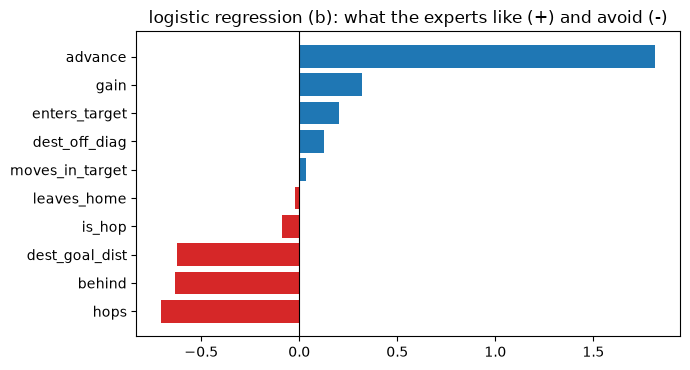

In [35]:
w = logistic["b"][-1].coef_[0]
order = np.argsort(w)
plt.figure(figsize=(7, 3.8))
plt.barh([FEATURES[i] for i in order], w[order], color=["tab:red" if v < 0 else "tab:blue" for v in w[order]])
plt.axvline(0, color="k", lw=0.8)
plt.title("logistic regression (b): what the experts like (+) and avoid (-)")
plt.tight_layout(); plt.show()

**Question 1.** Which three features matter most, and does that match how you
played Hoppers? Is there a weight whose sign surprises you? (Hint: two features
that measure almost the same thing share the credit.)

## Part 6. Neural network

A logistic regression only **adds** the effect of each input. A neural network
has **hidden layers**, so it can **combine** inputs ("this move is good *because*
there is a piece to hop over").

```
 input (400 or 10) ──► Dense 64, relu ──► Dense 32, relu ──► Dense 1, sigmoid ──► P(expert move)
```

### Exercise 2: `build_network(n_inputs)`

Return a compiled `keras.Sequential`: `keras.Input(shape=(n_inputs,))`,
`Dense(64, activation="relu")`, `Dense(32, activation="relu")`,
`Dense(1, activation="sigmoid")`, compiled with
`optimizer=keras.optimizers.Adam(1e-3)` and `loss="binary_crossentropy"`.
(Other sizes are fine; keep one sigmoid output at the end.)

In [36]:
from tensorflow import keras
keras.utils.set_random_seed(0)

def build_network(n_inputs):
    model = keras.Sequential([
        keras.Input(shape=(n_inputs,)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model

In [37]:
test = build_network(10)
out = test(np.zeros((3, 10), np.float32)).numpy()
assert out.shape == (3, 1) and ((out > 0) & (out < 1)).all(), "one sigmoid output per row"
assert test.optimizer is not None, "compile the model"
print("OK"); test.summary()

OK


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

### Exercise 3: training with fresh negatives

At every **epoch** (pass over the data), draw **new** random siblings with
`make_table`, so in 8 epochs the network sees about 80 different bad moves per
position instead of 10. For each epoch: `X, y = make_table(train, encode, K, rng)`,
then `hist = model.fit(X, y, batch_size=256, epochs=1, verbose=0)`.

In [38]:
def train_network(encode, n_inputs, epochs=8):
    model = build_network(n_inputs)
    rng = np.random.default_rng(1)
    for epoch in range(epochs):
        X, y = make_table(train, encode, K, rng)
        hist = model.fit(X, y, batch_size=256, epochs=1, verbose=0)
        print(f"   epoch {epoch + 1}: loss {hist.history['loss'][0]:.4f}")
    return model

In [39]:
network = {}
for kind, enc in ENCODERS.items():
    t = time.time()
    print(f"network, input ({kind}):")
    network[kind] = train_network(enc, n_inputs=400 if kind == "a" else 10)
    print(f"   trained in {time.time() - t:.0f}s")

network, input (a):
   epoch 1: loss 0.2066
   epoch 2: loss 0.1485
   epoch 3: loss 0.1390
   epoch 4: loss 0.1342
   epoch 5: loss 0.1302
   epoch 6: loss 0.1274
   epoch 7: loss 0.1248
   epoch 8: loss 0.1222
   trained in 40s
network, input (b):
   epoch 1: loss 0.1926
   epoch 2: loss 0.1762
   epoch 3: loss 0.1733
   epoch 4: loss 0.1711
   epoch 5: loss 0.1693
   epoch 6: loss 0.1681
   epoch 7: loss 0.1672
   epoch 8: loss 0.1660
   trained in 189s


## Part 7. The agent, and which model plays best

`Scorer` wraps a model and its input: `scorer.scores(state, moves)` gives one
number per move, for any of the four models.

In [40]:
class Scorer:
    def __init__(self, model, encode):
        self.model, self.encode = model, encode
    def scores(self, state, moves):
        X = self.encode(state, moves)
        if hasattr(self.model, "predict_proba"):                 # scikit-learn
            return self.model.predict_proba(X)[:, 1]
        return self.model(X, training=False).numpy()[:, 0]       # Keras

scorers = {}
for kind, enc in ENCODERS.items():
    scorers[f"logistic ({kind})"] = Scorer(logistic[kind], enc)
    scorers[f"network  ({kind})"] = Scorer(network[kind], enc)

### Exercise 4: `choose_move(state, scorer)`

1. `moves = H.actions(state)`: the valid moves (from the rules)
2. if a move wins right now (`H.winner(H.result(state, a)) == state.to_move`), return it
3. `scores = scorer.scores(state, moves)`
4. return the move with the highest score (`np.argmax`)

In [41]:
def choose_move(state, scorer):
    moves = H.actions(state)
    for a in moves:
        if H.winner(H.result(state, a)) == state.to_move:
            return a
    scores = scorer.scores(state, moves)
    return moves[int(np.argmax(scores))]

In [42]:
s0 = H.initial_state()
a = choose_move(s0, scorers["logistic (b)"])
assert a in H.actions(s0), "the agent must return one of the valid moves"
print("first move of logistic (b):", a, "| OK")

first move of logistic (b): (1,1) -> (3,3) | OK


### How well does each model copy the experts?

On the **validation games**: how often is the expert's move the model's **1st**
choice, or in its **top 3**? Two baselines: random, and **gain** alone (the
course heuristic: the move that saves the most steps).

In [43]:
def copy_rate(samples, score_fn, ks=(1, 3)):
    hits = {k: 0.0 for k in ks}
    for state, moves, idx in samples:
        s = np.asarray(score_fn(state, moves), dtype=float)
        better, ties = (s > s[idx]).sum(), (s == s[idx]).sum()
        for k in ks:
            hits[k] += max(0.0, min(1.0, (k - better) / ties))   # ties are shared
    return {k: v / len(samples) for k, v in hits.items()}

baselines = {
    "random": lambda s, m: np.random.default_rng(len(m)).random(len(m)),
    "gain (heuristic)": lambda s, m: encode_features(s, m)[:, 0],
}
check = val[::2]                                   # half of the validation moves, to be quick
print(f"{'':20s}{'1st':>8s}{'top 3':>8s}")
for name, fn in list(baselines.items()) + [(n, sc.scores) for n, sc in scorers.items()]:
    c = copy_rate(check, fn)
    print(f"{name:20s}{c[1]:8.1%}{c[3]:8.1%}")

                         1st   top 3
random                  0.9%    3.0%
gain (heuristic)       16.2%   30.1%
logistic (a)           28.5%   52.0%
network  (a)           33.8%   58.9%
logistic (b)           32.8%   56.6%
network  (b)           33.1%   56.4%


### And how well does each one **play**?

`match` plays each random opening twice, swapping colors, so nobody keeps the
first-move advantage. 10 games against a **random** player and 10 against the
**greedy** player (the course heuristic: always the move with the biggest gain).

In [44]:
def random_player(state):
    return random.Random(hash(state)).choice(H.actions(state))      # same board -> same choice

def greedy_player(state):
    moves = H.actions(state)
    rng = random.Random(hash(state))                                  # ties broken the same way every time
    gain = encode_features(state, moves)[:, 0] + 1e-3 * np.array([rng.random() for _ in moves])
    return moves[int(np.argmax(gain))]

def in_target(state, p):
    return sum(1 for r, c in H.pieces_of(state, p) if H.in_camp(H.opponent(p), r, c))

def play_game(p1, p2, opening, seed, max_plies=400):
    rng, s = random.Random(seed), H.initial_state()
    for ply in range(max_plies):
        if H.terminal(s):
            break
        player = p1 if s.to_move == H.P1 else p2
        s = H.result(s, rng.choice(H.actions(s)) if ply < opening else player(s))
    w = H.winner(s)
    if w is None:                                  # move limit: more pieces in the target camp
        n1, n2 = in_target(s, H.P1), in_target(s, H.P2)
        w = H.P1 if n1 > n2 else H.P2 if n2 > n1 else 0
    return w

def match(agent, opponent, pairs=5, seed=1):
    wins = losses = 0
    for i in range(pairs):
        opening = random.Random(seed * 100 + i).choice([2, 4, 6])
        for me, game in ((H.P1, (agent, opponent)), (H.P2, (opponent, agent))):
            w = play_game(*game, opening, seed * 100 + i)
            wins += w == me
            losses += w == H.opponent(me)
    return wins, losses

print(f"{'':20s}{'vs random':>12s}{'vs greedy':>12s}")
for name, sc in scorers.items():
    agent = lambda state, sc=sc: choose_move(state, sc)
    r, g = match(agent, random_player), match(agent, greedy_player)
    print(f"{name:20s}{r[0]:5d} - {r[1]:<4d}{g[0]:5d} - {g[1]:<4d}")

                       vs random   vs greedy
logistic (a)           10 - 0       5 - 5   
network  (a)           10 - 0      10 - 0   
logistic (b)           10 - 0       9 - 1   
network  (b)           10 - 0       1 - 9   


**Question 2.** Is the model that copies the experts best also the one that wins
most against the greedy player? Why could a model match the experts more often
and still play worse? (When it does **not** pick the expert's move, is its
choice a reasonable move?)

**Question 3.** Input (a) or (b): which works better with logistic regression,
and which with the network? Why?

## Part 8. Your tournament agent: `my_ml_agent.py`

Pick the model you want (by the results above). `export_agent` saves **two files**:

- **your trained model**, in the library's own format:
  `my_model.keras` for a network (TensorFlow/Keras), or `my_model.joblib` for a
  logistic regression (scikit-learn);
- **`my_ml_agent.py`**: the tournament agent. It holds the code of
  `hoppers_inputs.py` (Part 3), so it turns boards into numbers exactly as in
  training, loads your model file, and defines `choose_action(state)` with the
  decision of Exercise 4.

In Colab both files are downloaded to your computer.

In [45]:
import joblib

AGENT_CODE = '''

# ---------------- the trained model (file written by the notebook) ----------------
import os
INPUT = "@@INPUT@@"              # the numbers the model reads: "a" (board) or "b" (features)
MODEL_FILE = "@@MODEL_FILE@@"    # keep it in the same folder as this file
_path = os.path.join(os.path.dirname(os.path.abspath(__file__)), MODEL_FILE)

if MODEL_FILE.endswith(".keras"):                    # a TensorFlow / Keras network
    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
    from tensorflow import keras
    _model = keras.models.load_model(_path)

    def _predict(X):
        return _model(X, training=False).numpy()[:, 0]
else:                                                # a scikit-learn model
    import joblib
    _model = joblib.load(_path)

    def _predict(X):
        return _model.predict_proba(X)[:, 1]


def scores(state, moves):
    return _predict(ENCODERS[INPUT](state, moves))


def choose_action(state):
    # the tournament calls this: the valid moves, a winning one if any, else the best-scored
    moves = actions(state)
    for a in moves:
        if winner(result(state, a)) == state.to_move:
            return a
    return moves[int(np.argmax(scores(state, moves)))]
'''

def export_agent(model, input_kind, path="my_ml_agent.py"):
    if hasattr(model, "predict_proba"):              # scikit-learn
        import sklearn
        model_file, needs = "my_model.joblib", f"scikit-learn {sklearn.__version__}"
        joblib.dump(model, model_file)
    else:                                            # Keras
        import tensorflow as tf
        model_file, needs = "my_model.keras", f"tensorflow {tf.__version__}"
        model.save(model_file)
    header = (f"# Hoppers ML agent (imitation learning), input ({input_kind}).\n"
              f"# Needs, in the same folder: {model_file} and hopperstournament.py.\n"
              f"# Needs installed: numpy and {needs} (the version it was trained with).\n")
    with open(path, "w") as f:
        f.write(header + open("hoppers_inputs.py").read()
                + AGENT_CODE.replace("@@INPUT@@", input_kind).replace("@@MODEL_FILE@@", model_file))
    return path, model_file, needs

In [46]:
BEST_MODEL, BEST_INPUT = "network", "a"            # <- your choice: "logistic"/"network", "a"/"b"

model = (logistic if BEST_MODEL == "logistic" else network)[BEST_INPUT]
agent_file, model_file, needs = export_agent(model, BEST_INPUT)

import my_ml_agent                                  # check: the agent loads the saved model and scores like it
importlib.reload(my_ml_agent)
for s, m, _ in val[:100]:
    np.testing.assert_allclose(my_ml_agent.scores(s, m), scorers[f"{BEST_MODEL:8s} ({BEST_INPUT})"].scores(s, m),
                               rtol=1e-4, atol=1e-6)
print(f"wrote {agent_file} and {model_file}: {BEST_MODEL}, input ({BEST_INPUT}) | the agent needs {needs} | OK")
print("against the greedy player, the agent file itself:", "%d - %d" % match(my_ml_agent.choose_action, greedy_player))

if "google.colab" in sys.modules:
    from google.colab import files
    files.download(agent_file)
    files.download(model_file)

wrote my_ml_agent.py and my_model.keras: network, input (a) | the agent needs tensorflow 2.21.0 | OK
against the greedy player, the agent file itself: 10 - 0


**In the tournament**, put `my_ml_agent.py` **and** your model file
(`my_model.keras` or `my_model.joblib`) in the folder with `hopperstournament.py`,
and use `my_ml_agent.py` like any agent: it defines `choose_action(state)`.
The computer that runs the tournament needs TensorFlow (for a `.keras` model)
or scikit-learn (for a `.joblib` model), ideally the version printed above:
`pip install tensorflow` or `pip install scikit-learn`. Loading TensorFlow takes
a few seconds when the agent is imported; after that each move takes a few
milliseconds.

Play it against your own tournament agent (your heuristic) and against your
classmates'.

**Question 4.** How did your model do against your own minimax agent? Your
model was trained on the moves of minimax agents: why does it still (probably)
lose to one? What does a minimax agent do at every move that your model never
does? (Idea for later: use the model inside a minimax, to explore only the 6
moves it likes best. That is how AlphaGo combined a network with search.)

## Deliverables

1. This notebook, run top to bottom, with Exercises 1-4 and the answers to Questions 1-4.
2. `my_ml_agent.py` and your model file (`my_model.keras` or `my_model.joblib`).

### Your answers


**Question 1.**
La que más pesa por mucho es `advance`, como 1.8, y después vienen `hops`, `behind` y `dest_goal_dist`, que andan por -0.6. Lo de `advance` y `dest_goal_dist` cuadra con mi agente del torneo, porque mi heurística también se basaba en la distancia a la meta (usaba distancia de Chebyshev y le daba 8 puntos por cada casilla más cerca). Y `enters_target` salió positivo, que también coincide, porque yo le daba 150 puntos a cada ficha que ya estaba en el campamento rival.
Donde no coincide es en `leaves_home`: yo castigaba con 15 puntos cada ficha que seguía en mi campamento inicial, y al modelo eso casi no le importó, salió en 0. Y `behind` negativa me pareció interesante, porque dice que los expertos prefieren mover las piezas que se quedaron atrás para no dejar ninguna tirada, y eso mi heurística no lo tenía directamente.
Lo que no me esperaba es que `hops` e `is_hop` salieran negativas, porque uno piensa que saltar siempre es bueno. Pero lo que pasa es que `advance` ya está contando lo bueno del salto, o sea cuánto avanzas, entonces se queda con todo el crédito. Y lo mismo con `gain`, que es la heurística del curso y solo quedó en 0.3, porque mide casi lo mismo que `advance` y se reparten.

**Question 2.**
En mi caso sí fue el mismo: la red con el tablero (a) fue la que más copió, 33.8%, y también la que mejor jugó, le ganó 10-0 al greedy. Pero lo chilero es la red (b), que copia 33.1%, más que la logística (b) que copia 32.8%, y aun así la red (b) perdió 1-9 contra el greedy mientras la logística (b) ganó 9-1. O sea, copian casi igual y juegan completamente diferente.
Eso pasa porque atinarle a la jugada exacta del experto no es lo mismo que jugar bien. Muchas veces hay varias jugadas que son igual de buenas, y si el modelo agarra otra, cuenta como que falló aunque no esté mal. Lo que de verdad importa es qué hace cuando no copia: si se equivoca con jugadas que igual son decentes, gana; si se equivoca con jugadas malas, como regresarse o dejar piezas atrás, pierde. Y eso el porcentaje no te lo dice.

**Question 3.**
Con la regresión logística le fue mejor con la (b): copió 32.8% contra 28.5% con el tablero, y le ganó 9-1 al greedy contra un 5-5. Y tiene sentido, porque la logística solo le pone un peso a cada número y los suma, entonces con el tablero crudo solo ve casillas sueltas, no entiende cosas como "aquí hay una pieza y atrás está vacío, entonces puedo saltar". Con las features ya le das todo calculado y solo tiene que ver qué importa más.
Con la red fue al revés: la (a) fue la mejor de todas, y la (b) fue la peor jugando. La red tiene capas ocultas que sí pueden combinar casillas, entonces con el tablero completo pudo encontrar patrones por su cuenta. Con solo 10 números no tiene mucho que combinar. Hasta en el entrenamiento se ve: con el tablero el loss bajó a 0.12 y con las features se quedó en 0.17.

**Question 4.**
Aquí me sorprendió, porque le gané a mi propio minimax 4-0 con el modelo (lo puse con 1 segundo por jugada, igual que como se generaron los datos del lab). La pregunta dice que probablemente pierde, y a mí me pasó al revés.
Creo que es por varias cosas. Primero, con 1 segundo mi minimax casi nunca terminaba de buscar a profundidad 3, entonces en la práctica solo veía como 2 jugadas adelante. En mi proyecto lo tenía con 28 segundos, ahí seguro juega mejor. Segundo, mi heurística mide la distancia de cada ficha a la casilla más cercana del campamento rival, que sirve para avanzar pero no para acomodar bien las fichas al final y llenar el campamento. El modelo en cambio aprendió de 6 agentes distintos y miles de jugadas, entonces agarró lo mejor de varias heurísticas, no solo de la mía. Y también son solo 4 partidas, no es como para decir que el modelo es mejor siempre.
Igual la diferencia de fondo sigue ahí: el minimax en cada turno simula "si muevo esto, él mueve esto, y luego yo...", y el modelo nunca hace eso, solo ve las jugadas de ese momento, les pone nota y agarra la más alta. Contra un minimax con más tiempo o con mejor heurística, seguro le cuesta más. Lo ideal sería juntar las dos cosas: usar el modelo dentro del minimax para que solo revise las 6 jugadas que más le gustan, así busca menos y más profundo, que es lo que hizo AlphaGo.

In [49]:
import hoppers as MH
from minimax_agent import MinimaxAgent

mi_minimax = MinimaxAgent(depth=3, time_limit=1.0)

def mi_agente(state):
    s = MH.State(board=state.board, turn=state.to_move)
    path = mi_minimax.choose_action(s)
    for a in H.actions(state):
        if a.origin == path[0] and a.destination == path[-1]:
            return a

print("modelo ML vs mi minimax:", "%d - %d" % match(my_ml_agent.choose_action, mi_agente, pairs=2))


modelo ML vs mi minimax: 4 - 0
